Virtual Environment and Requests Module

In [4]:
# sending a request and logging the response code
import requests
r = requests.get("https://api.github.com/users/Connor-SM")
print(r)
print(type(r))

<Response [200]>
<class 'requests.models.Response'>


In [6]:
# accessing the content that we requested from the URL
data = r.content
print(data)

b'{"login":"Connor-SM","id":20958711,"node_id":"MDQ6VXNlcjIwOTU4NzEx","avatar_url":"https://avatars.githubusercontent.com/u/20958711?v=4","gravatar_id":"","url":"https://api.github.com/users/Connor-SM","html_url":"https://github.com/Connor-SM","followers_url":"https://api.github.com/users/Connor-SM/followers","following_url":"https://api.github.com/users/Connor-SM/following{/other_user}","gists_url":"https://api.github.com/users/Connor-SM/gists{/gist_id}","starred_url":"https://api.github.com/users/Connor-SM/starred{/owner}{/repo}","subscriptions_url":"https://api.github.com/users/Connor-SM/subscriptions","organizations_url":"https://api.github.com/users/Connor-SM/orgs","repos_url":"https://api.github.com/users/Connor-SM/repos","events_url":"https://api.github.com/users/Connor-SM/events{/privacy}","received_events_url":"https://api.github.com/users/Connor-SM/received_events","type":"User","user_view_type":"public","site_admin":false,"name":"Connor Milliken","company":"HubSpot, Inc.","b

In [7]:
# converting data from JSON into a Python dictionary and outputing all key-values pairs
data = r.json()        # converting the data from a string to a dictionary
for k, v in data.items():
    print("Key: {} \t Value: {}".format(k, v))
print(data["name"])           # accessing data directly

Key: login 	 Value: Connor-SM
Key: id 	 Value: 20958711
Key: node_id 	 Value: MDQ6VXNlcjIwOTU4NzEx
Key: avatar_url 	 Value: https://avatars.githubusercontent.com/u/20958711?v=4
Key: gravatar_id 	 Value: 
Key: url 	 Value: https://api.github.com/users/Connor-SM
Key: html_url 	 Value: https://github.com/Connor-SM
Key: followers_url 	 Value: https://api.github.com/users/Connor-SM/followers
Key: following_url 	 Value: https://api.github.com/users/Connor-SM/following{/other_user}
Key: gists_url 	 Value: https://api.github.com/users/Connor-SM/gists{/gist_id}
Key: starred_url 	 Value: https://api.github.com/users/Connor-SM/starred{/owner}{/repo}
Key: subscriptions_url 	 Value: https://api.github.com/users/Connor-SM/subscriptions
Key: organizations_url 	 Value: https://api.github.com/users/Connor-SM/orgs
Key: repos_url 	 Value: https://api.github.com/users/Connor-SM/repos
Key: events_url 	 Value: https://api.github.com/users/Connor-SM/events{/privacy}
Key: received_events_url 	 Value: https://

In [ ]:
# output specific key-value pairs from data
r = requests.get("https://api.github.com/search/repositories?q=language:python")
data = r.json()
print(data["total_count"])   # output the total number of repositories that use python

Pandas

In [1]:
# importing the pandas library
import pandas as pd

In [3]:
# using the from_dict method to convert dictionary into Pandas DataFrame
import random
random.seed(3)       # generate same random numbers every time, number used doesn't matter
names = [ "Jess", "Jordan", "Sandy", "Ted", "Barney", "Tyler", "Rebecca" ]
ages = [ random.randint(18, 35) for x in range(len(names) )]
people = { "names" : names, "ages": ages }
df = pd.DataFrame.from_dict(people)
print(df)

     names  ages
0     Jess    25
1   Jordan    35
2    Sandy    22
3      Ted    29
4   Barney    33
5    Tyler    20
6  Rebecca    18


In [4]:
# directly selecting a column in Pandas
print(df["ages"])
print( df["ages"][3])     # select the value of "ages" in the fourth row(0 index based)
# print(df[4])    doesn't work, 4 is not a column name

0    25
1    35
2    22
3    29
4    33
5    20
6    18
Name: ages, dtype: int64
29


In [5]:
# directly selecting a record in Pandas using .loc
print(df.loc[0])
print(df.loc[0]["names"])

names    Jess
ages       25
Name: 0, dtype: object
Jess


In [6]:
# slicing a DataFrame to grab specific records
print(df[2:5])

    names  ages
2   Sandy    22
3     Ted    29
4  Barney    33


In [7]:
df.head(5)

,names,ages
0,Jess,25
1,Jordan,35
2,Sandy,22
3,Ted,29
4,Barney,33


In [8]:
# accessing the bottom 3 records using .tail() method
df.tail(3)

,names,ages
4,Barney,33
5,Tyler,20
6,Rebecca,18


In [9]:
# accessing the column headers(keys) using the .keys() method
headers = df.keys()
print(headers)

Index(['names', 'ages'], dtype='object')


In [10]:
# checking the shape, which is the number of records and columns
print(df.shape)

(7, 2)


In [11]:
# checking the general statistics of the DataFrame using .describe(), only works on numerical columns
df.describe()

,ages
count,7.000000
mean,26.000000
std,6.531973
min,18.000000
25%,21.000000
50%,25.000000
75%,31.000000
max,35.000000


In [13]:
# sort based on a given column, but keep the DataFrame in tact using sort.values
df = df.sort_values("ages")
df.head(5)

,names,ages
6,Rebecca,18
5,Tyler,20
2,Sandy,22
0,Jess,25
3,Ted,29


In [14]:
# using a conditional to create a true/false column to work with
can_drink = df["ages"] > 21
print(can_drink)

6    False
5    False
2     True
0     True
3     True
4     True
1     True
Name: ages, dtype: bool


In [16]:
# using subsetting to filter our records and keep DataFrame intact
df[ df["ages"] > 21]

,names,ages
2,Sandy,22
0,Jess,25
3,Ted,29
4,Barney,33
1,Jordan,35


# Column Transformations

In [17]:
# generating a new column of fake data for each record in the DataFrame to represent customer tenure
random.seed(321)
tenure = [ random.randint(0, 10) for x in range( len(df) ) ]
df["tenure"] = tenure           # same as adding a new key value pair in a dictionary
df.head()

,names,ages,tenure
6,Rebecca,18,4
5,Tyler,20,6
2,Sandy,22,2
0,Jess,25,5
3,Ted,29,8


In [19]:
# apply()
# feature engineering a new column from known data using a UDF
def ageGroup(age):
    return "Teenager" if age < 21 else "Adult"
df["age_group"] = df["ages"].apply(ageGroup)
df.head(10)

,names,ages,tenure,age_group
6,Rebecca,18,4,Teenager
5,Tyler,20,6,Teenager
2,Sandy,22,2,Adult
0,Jess,25,5,Adult
3,Ted,29,8,Adult
4,Barney,33,7,Adult
1,Jordan,35,5,Adult


In [20]:
# groupby()
# grouping the records together to count how many records in each group
df.groupby("age_group", as_index=False).count().head()

,age_group,names,ages,tenure
0,Adult,5,5,5
1,Teenager,2,2,2


In [ ]:
# mean()
#grouping the data to see averages of all columns
df.groupby("age_group", as_index=False).mean().head()

In [ ]:
Matplotlib

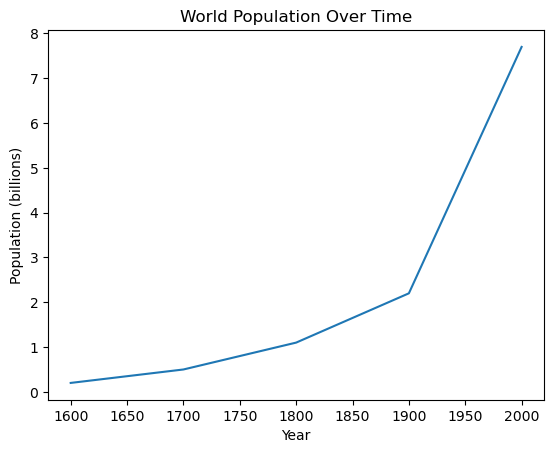

In [6]:
# importing the matplotlib library from matplotlib import
import matplotlib.pyplot as plt

# creating a line plot using x and y coordinates
x, y = [ 1600, 1700, 1800, 1900, 2000 ], [ 0.2, 0.5, 1.1, 2.2, 7.7 ]
plt.plot(x, y)      # creates the line
plt.title("World Population Over Time")
plt.xlabel("Year")
plt.ylabel("Population (billions)")
plt.show( )

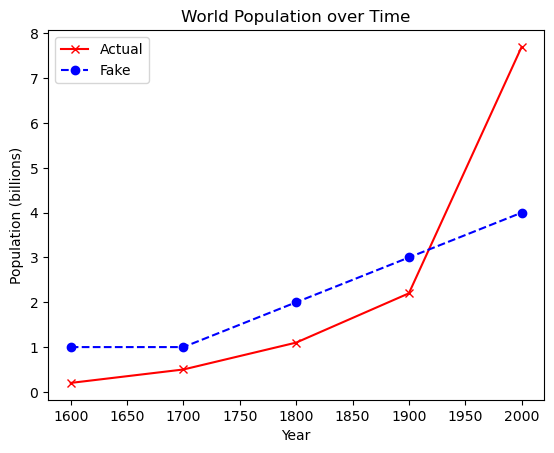

In [7]:
# creating a line plot with multiple lines
x1, y1 = [ 1600, 1700, 1800, 1900, 2000 ], [ 0.2, 0.5, 1.1, 2.2, 7.7 ]
x2, y2 = [ 1600, 1700, 1800, 1900, 2000 ], [ 1, 1, 2, 3, 4 ]
plt.plot(x1, y1, "rx-", label="Actual")    # create a red solid line with x dots
plt.plot(x2, y2, "bo--", label="Fake")     # create a blue dashed line with circle dots
plt.title("World Population over Time")
plt.xlabel("Year")
plt.ylabel("Population (billions)")
plt.legend( )         # shows labels in best corner
plt.show( )

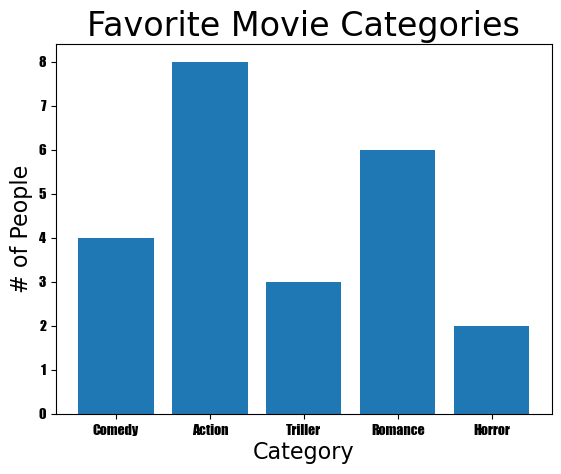

In [8]:
# creating a bar plot using x and y coordinates
num_people, categories = [ 4, 8, 3, 6, 2 ], [ "Comedy", "Action", "Triller", "Romance", "Horror" ]
plt.bar(categories, num_people)
plt.title("Favorite Movie Categories", fontsize=24)
plt.xlabel("Category", fontsize=16)
plt.ylabel("# of People", fontsize=16)
plt.xticks(fontname="Fantasy")
plt.yticks(fontname="Fantasy")
plt.show( )

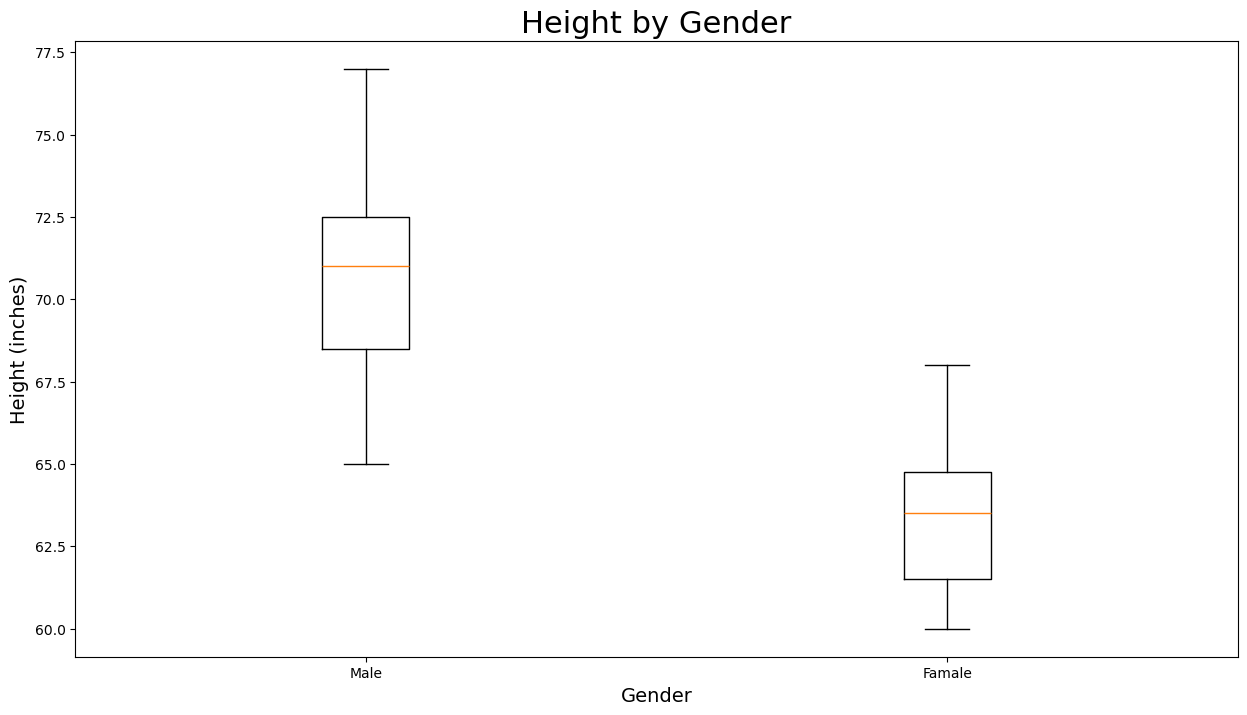

In [11]:
# Box Plot
# Creating a box plot - showing height data for male-famale
males, famales = [ 72, 68, 65, 77, 73, 71, 69 ], [ 60, 65, 68, 61, 63, 64 ]
heights = [ males, famales ]
plt.figure(figsize=(15, 8))         # makes chart bigger
plt.boxplot(heights)                # takes in list of data, each box is its' own array, heights contains two lists
plt.xticks( [1, 2 ], [ "Male", "Famale" ] )    # sets number of ticks and labels on x-axis
plt.title("Height by Gender", fontsize=22)
plt.ylabel("Height (inches)", fontsize=14)
plt.xlabel("Gender", fontsize=14)
plt.show( )


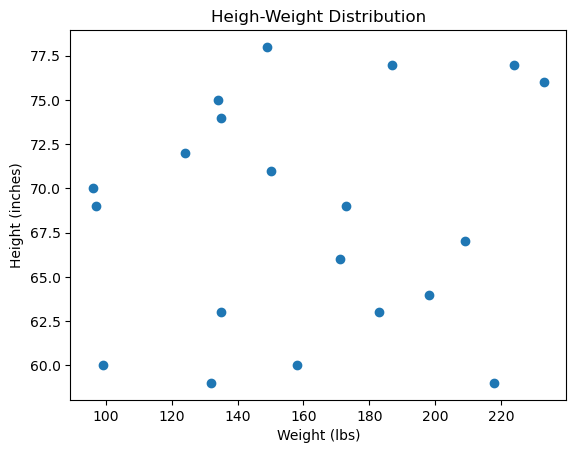

In [17]:
# Scatter Plot
# creating a scatter plot to represent height-weight distribution
import random 
random.seed(2)
height = [ randint(58, 78) for x in range(20) ]  # 20 records between 4'10" and 6'6"
weight = [ randint(90, 250) for x in range(20) ] # 20 records between 90lbs. and 250lbs.
plt.scatter(weight, height)
plt.title("Heigh-Weight Distribution")
plt.xlabel("Weight (lbs)")
plt.ylabel("Height (inches)")
plt.show( )

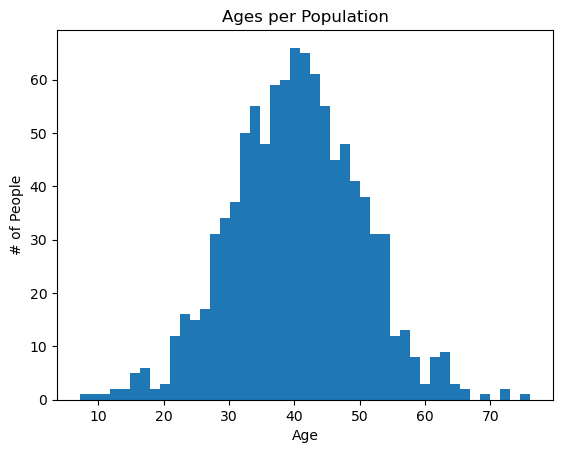

In [18]:
# Histogram
#j creating a histogram to show age data for a fake population
import numpy as np          # import the numpy module to generate data
np.random.seed(5)
ages = [ np.random.normal(loc=40, scale=10) for x in range(1000) ]   # ages distributed around 40
plt.hist(ages, bins=45)       # bins is the number of bars
plt.title("Ages per Population")
plt.xlabel("Age")
plt.ylabel("# of People")
plt.show( )

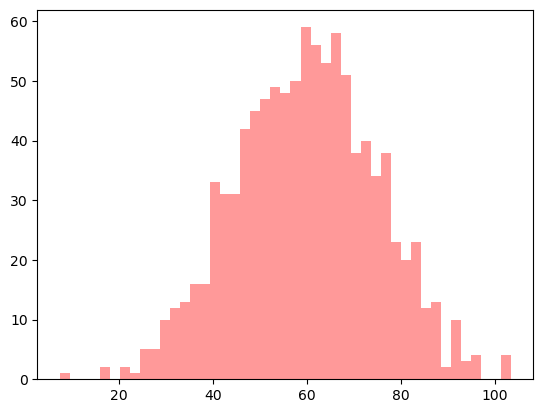

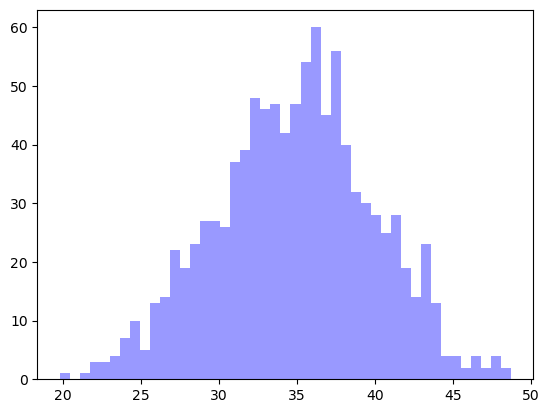

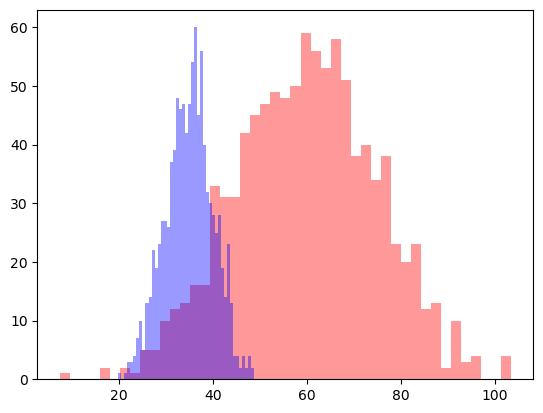

In [19]:
# showing the importance of histogram's display central distribution
florida = [ np.random.normal(loc=60, scale=15) for x in range(1000) ]     # assume numpy is imported
california = [ np.random.normal(loc=35, scale=5) for x in range(1000) ]   
# chart 1
plt.hist(florida, bins=45, color="r", alpha=0.4)          # alpha is opacity, making it see through
plt.show( )
# chart 2
plt.hist(california, bins=45, color="b", alpha=0.4)       # alpha is opacity, making it see through
plt.show()
# chart 3
plt.hist(florida, bins=45, color="r", alpha=0.4)          # alpha is opacity, making it see through
plt.hist(california, bins=45, color="b", alpha=0.4)       # alpha is opacity, making it see through
plt.show()

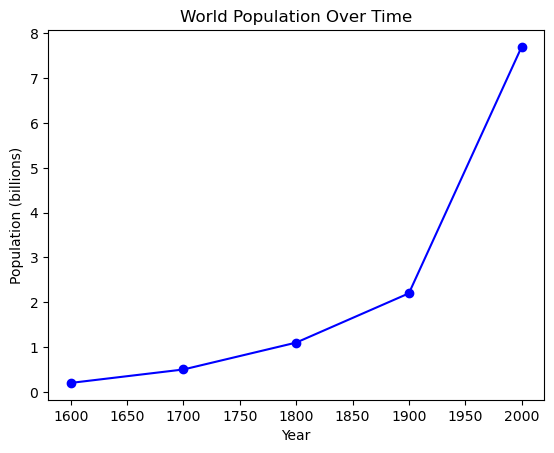

In [20]:
# using savefig method to save the chart as a jpg to the local folder
x, y = [ 1600, 1700, 1800, 1900, 2000 ], [ 0.2, 0.5, 1.1, 2.2, 7.7 ]
plt.plot(x, y, "bo-")        # creates a blue solid line with circle dots
plt.title("World Population Over Time")
plt.xlabel("Year")
plt.ylabel("Population (billions)")
plt.savefig("population.jpg")

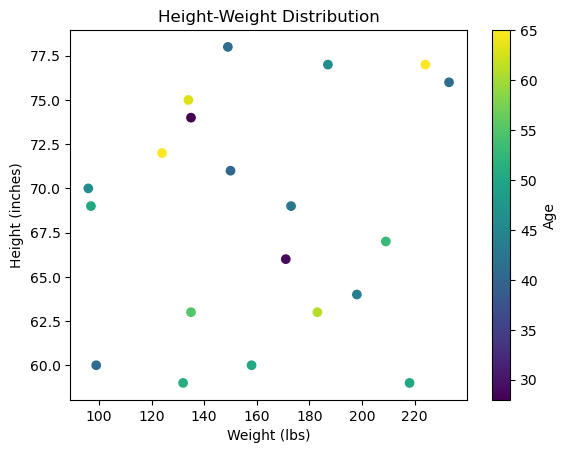

In [21]:
# creating a scatter plot to represent height-weight distribution
import random
random.seed(2)
height = [ randint(58, 78) for x in range(20) ]
weight = [ randint(90, 250) for x in range(20) ]
age = [ randint(18, 65) for x in range(20) ]       # 20 records between 18 and 65 years old
plt.scatter(weight, height, c=age)                # sets the age list to be shown by color
plt.title("Height-Weight Distribution")
plt.xlabel("Weight (lbs)")
plt.ylabel("Height (inches)")
plt.colorbar(label="Age")                  # adds color bar to right side
plt.show( )
           

"Web Scraping"

In [2]:
# importing the beautiful soup and requests library
import bs4
import requests

In [4]:
# performing a request and outputting the status code 
page = requests.get("http://www.arthurleej.com/e-love.html")
print(page)

<Response [465]>


In [ ]:
# outputting the request response content
print(page.content)

In [ ]:
# turning the response into a BeautifulSoup object to extract data
soup = BeautifulSoup(page.content, "html.parser")
print( soup.prettify() )

In [ ]:
# using the find method to scrape the text within the first bold tag
title = soup.find("b")
print(title)
print( title.get_text() )          # extracts all text within element

In [ ]:
# find_all()
# get all text within the bold element tag then ouput each
poem_text = soup.find_all("b")
for text in poem_text:
    print( text.get_text() )

In [ ]:
# finding an element by specific attribute key-values
page = requests.get("https://github.com/Connor-SM")
soup = BeautifulSoup(page.content, "html.parser")
username = soup.find( "span", attrs={ "class" : "vcard-surname" } )    # will show that element has class of vcard-username among others
print(username)     # will show that element has class of vcard-username among others
print( username.get_text( ) )